# evaluación y transferencia: Comparación con métodos publicados

**Nivel:** 3 **Requisitos previos:** Evaluación, transferencia y límites nivel 1 **Tiempo de lectura:** 25 minutos

**Pregunta:** ¿Cómo se compara la referencia aprendida más fuerte con la política protegida en una tarea C01 idéntica?

## Objetivos

Esta lección investiga la pregunta: ¿Cómo se compara la referencia aprendida más fuerte con la política protegida en una tarea C01 idéntica?

## Preparación

Las versiones siguientes están fijadas en `notebooks/requirements.txt` y también constan en los metadatos de este notebook; ```bash pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2 ```

In [1]:
# Importa la API publicada de políticas y las dependencias fijadas de gráficos y ejecución.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")
import sys
ROOT = Path('../../../').resolve()
sys.path.insert(0, str(ROOT))
checkpoint_dir = Path(os.environ.get('NEURAXIS_CHECKPOINTS', str(ROOT / 'models/checkpoints')))
planner_model = os.environ.get('NEURAXIS_NOTEBOOK_MODEL')
planner = OllamaPlanner(planner_model) if planner_model else None
sys.path.insert(0, str(ROOT / 'notebooks'))

reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Datos
El notebook lee artefactos comprometidos del producto. Propietario: Neuraxis. Repositorio: https://github.com/fsantibanezleal/CAOS_Neuraxis. Licencia: Apache-2.0. El JSON es un artefacto experimental propio y congelado; este notebook no redistribuye datos de benchmarks externos;

Este notebook lee `data/derived/index.json` y las trazas listadas. La ejecución usa un espacio aislado de caso Reflexmesh; Para métodos aprendidos, descarga los activos públicos exactos con `python -m reflexmesh; Cli fetch-models --destination models/checkpoints --version v0; 01.000` y define `NEURAXIS_CHECKPOINTS` hacia esa carpeta; El manifiesto de publicación verifica los hashes. M09/M10 se leen desde trazas congeladas, salvo que `NEURAXIS_NOTEBOOK_MODEL` indique explícitamente un modelo Ollama local configurado;

Artefactos de esta lección:

- `data/derived/index.json` - `data/derived/benchmark-adequacy.json` - `data/derived/research.json` - `data/derived/semantic-transfer/index.json` - `data/derived/semantic-transfer/report.json` - `data/derived/episodes/M01-C01-nominal-40000; - `data/derived/episodes/M04-C01-nominal-40000; - `data/derived/episodes/M09-C01-nominal-40000; - `data/derived/episodes/M12-C01-nominal-40000; json`

In [2]:
# Load manifest-verified evidence and keep failures in every denominator.
import sys
sys.path.insert(0, str(ROOT / 'notebooks'))
from lesson_support import load_lesson_evidence
selected_methods = trace_methods = ['M01', 'M04']
sample_case, seed = 'C01', 40000
evidence = load_lesson_evidence(
    ROOT, topic='05-evaluation-and-transfer', methods=tuple(trace_methods),
    sample_case=sample_case, seed=seed,
    include_core=False, include_transfer=True,
)
index, audit = evidence['index'], evidence['audit']
records, case_records = evidence['records'], evidence['case_records']
print('Hash-verified records:', len(records), '| case variants:', len(case_records))
transfer, transfer_report = evidence['transfer'], evidence['transfer_report']


Hash-verified records: 2 | case variants: 12


### Comparar métodos entre variantes: evaluación y transferencia

La comparación debe preservar familias y denominadores, porque un resultado central no predice el desempeño en transferencia.

## Método

Benchmarks de uso de herramientas como ToolSandbox, SWE-bench y tau-bench motivan condiciones con estado y herramientas cambiantes, pero Neuraxis ejecuta subconjuntos locales y no afirma reproducir un benchmark completo. La transferencia se mantiene separada del núcleo saturado de 14.400 episodios. El gráfico emparejado M01/M04 es solo una ilustración reproducible; la comparación requiere denominadores completos con hash y el carril retenido de transferencia. La ventaja observada de M04 describe este conjunto, no una clasificación universal. Si los resultados son idénticos entre semillas, el intervalo por semilla es degenerado; la incertidumbre debe reflejar variación entre familias o declarar que no existe intervalo empírico. Una afirmación de transferencia necesita particiones sin composiciones casi duplicadas, plantillas compartidas ni etiquetas filtradas entre entrenamiento y evaluación. La conclusión reproducible queda acotada a las operaciones medidas, artefactos publicados y supuestos del entorno; no se generaliza a autonomía abierta sin evidencia nueva. Una extensión útil reconstruye el denominador desde el manifiesto y verifica que la partición retenida excluya composiciones relacionadas antes de comparar métodos.

### evaluación y transferencia · nivel 3 | Verifica la auditoría y los bytes de cada traza antes de interpretar resultados.

### evaluación y transferencia · nivel 3 | Ejecuta las políticas publicadas y compara la corrida

### evaluación y transferencia · nivel 3 | Compara la secuencia completa y no solo la primera acción

### evaluación y transferencia · nivel 3 | Recalcula resultados por variante desde todas las trazas del caso

In [3]:
# Lee todas las semillas del caso elegido y conserva cada episodio fallido en el denominador.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "éxitos=",
        sum(values),
        "episodios=",
        len(values),
        "tasa=",
        round(sum(values) / len(values), 3),
    )


M01 boundary éxitos= 10 episodios= 10 tasa= 1.0
M01 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M01 duplicate_event éxitos= 10 episodios= 10 tasa= 1.0
M01 nominal éxitos= 10 episodios= 10 tasa= 1.0
M01 stale_conflict éxitos= 10 episodios= 10 tasa= 1.0
M01 unavailable_dependency éxitos= 10 episodios= 10 tasa= 1.0
M04 boundary éxitos= 10 episodios= 10 tasa= 1.0
M04 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M04 duplicate_event éxitos= 10 episodios= 10 tasa= 1.0
M04 nominal éxitos= 10 episodios= 10 tasa= 1.0
M04 stale_conflict éxitos= 10 episodios= 10 tasa= 1.0
M04 unavailable_dependency éxitos= 10 episodios= 10 tasa= 1.0


### evaluación y transferencia · nivel 3 | Visualiza el estrés por variante sin mezclar familias

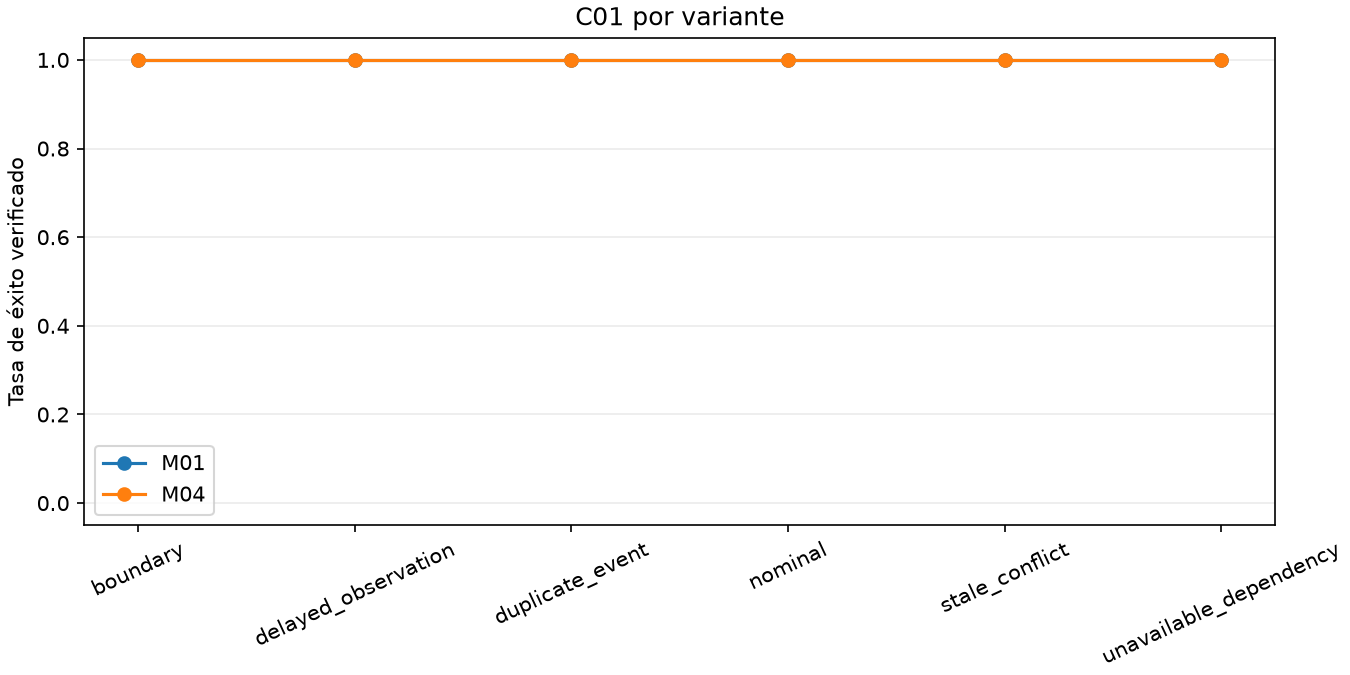

In [4]:
# Cada punto resume las semillas de una sola variante del caso, no el benchmark completo.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito verificado")
ax.set_title(sample_case + " por variante")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


### evaluación y transferencia · nivel 3 | Conserva transferencia semántica en su propio carril

C01 es un ejemplo central;

El gráfico 1, nivel 3, resume resultados centrales conservando los fallos para C01. El gráfico 1 ubica resultados centrales conservando los fallos en la familia diseñada C01 de nivel 3; Interpreta resultados centrales conservando los fallos en el gráfico 1 para C01 con su traza y poscondición antes de llamarlo mejora del control.

### Informar los agregados de transferencia auditados por separado

El índice y el conteo de episodios se verifican contra su auditoría independiente antes de mostrar estos totales por método.

In [5]:
# Muestra los agregados de transferencia separados, cuyos hashes ya se verificaron en la frontera de datos.
for row in transfer["aggregate_results"]:
    print(
        row["method_id"],
        "éxitos=",
        round(row["task_success"] * row["episodes"]),
        "/",
        row["episodes"],
        "tasa=",
        row["task_success"],
    )
print(
    "Episodios de transferencia verificados:",
    transfer_report["episodes_checked"],
    "| familias reservadas:",
    len(transfer["cases"]),
)


M01 éxitos= 0 / 128 tasa= 0.0
M02 éxitos= 0 / 128 tasa= 0.0
M03 éxitos= 0 / 128 tasa= 0.0
M04 éxitos= 2 / 128 tasa= 0.015625
M05 éxitos= 0 / 128 tasa= 0.0
M06 éxitos= 1 / 128 tasa= 0.0078125
M07 éxitos= 0 / 128 tasa= 0.0
M08 éxitos= 6 / 128 tasa= 0.046875
M09 éxitos= 38 / 128 tasa= 0.296875
M10 éxitos= 0 / 128 tasa= 0.0
M11 éxitos= 0 / 128 tasa= 0.0
M12 éxitos= 18 / 128 tasa= 0.140625
Episodios de transferencia verificados: 1536 | familias reservadas: 8


### Leer el resumen de transferencia vinculado por hash

Los resúmenes por método y familia vinculados al manifiesto conservan el denominador completo sin volver a abrir cada archivo de episodio.

In [6]:
# Lee los resúmenes de transferencia vinculados por hash, sin reabrir los 1.536 archivos de episodios.
for row in transfer_report["methods"]:
    print(
        row["method_id"],
        "éxitos=",
        row["successes"],
        "/",
        row["episodes"],
        "tasa=",
        round(row["successes"] / row["episodes"], 4),
    )
print("Resultados de transferencia por familia reservada:")
for row in transfer_report["by_family"]:
    print(row["family"], row["methods"])
print("Auditoría emparejada de M12 guardada:", transfer_report["m12_paired"])


M01 éxitos= 0 / 128 tasa= 0.0
M02 éxitos= 0 / 128 tasa= 0.0
M03 éxitos= 0 / 128 tasa= 0.0
M04 éxitos= 2 / 128 tasa= 0.0156
M05 éxitos= 0 / 128 tasa= 0.0
M06 éxitos= 1 / 128 tasa= 0.0078
M07 éxitos= 0 / 128 tasa= 0.0
M08 éxitos= 6 / 128 tasa= 0.0469
M09 éxitos= 38 / 128 tasa= 0.2969
M10 éxitos= 0 / 128 tasa= 0.0
M11 éxitos= 0 / 128 tasa= 0.0
M12 éxitos= 18 / 128 tasa= 0.1406
Resultados de transferencia por familia reservada:
D01 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 0, 'M05': 0, 'M06': 0, 'M07': 0, 'M08': 0, 'M09': 6, 'M10': 0, 'M11': 0, 'M12': 1}
D02 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 1, 'M05': 0, 'M06': 0, 'M07': 0, 'M08': 0, 'M09': 1, 'M10': 0, 'M11': 0, 'M12': 2}
D03 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 0, 'M05': 0, 'M06': 1, 'M07': 0, 'M08': 1, 'M09': 9, 'M10': 0, 'M11': 0, 'M12': 6}
D04 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 0, 'M05': 0, 'M06': 0, 'M07': 0, 'M08': 1, 'M09': 3, 'M10': 0, 'M11': 0, 'M12': 0}
D05 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 0, 'M05': 0, 'M06': 0, 'M07': 

### Evidencia de la matriz central completa

El índice central se verifica por hash contra su resumen de auditoría. Usa sus denominadores guardados y el conteo de variación entre semillas para la matriz completa; Las victorias y derrotas emparejadas de abajo se limitan a la muestra única C01 nominal cargada arriba. Las tasas marginales no revelan las victorias emparejadas de toda la matriz. El informe de transferencia estructural está vinculado por hash a su propio índice.

In [7]:
# Usa el resumen de auditoría vinculado al índice para la matriz completa y sus agregados para las tasas.
audit_methods = {row["method_id"]: row for row in audit["methods"]}
print("Episodios verificados:", audit["episodes_checked"])
print(
    "Celdas caso-variante-método con variación por semilla:",
    audit["seed_variable_cells"],
    "/",
    audit["case_variant_method_cells"],
)
for row in sorted(index["aggregate_results"], key=lambda value: value["method_id"]):
    audit_row = audit_methods[row["method_id"]]
    print(
        row["method_id"],
        audit_row["successes"],
        "/",
        audit_row["episodes"],
        "tasa=",
        round(row["task_success"], 4),
    )


Episodios verificados: 14400
Celdas caso-variante-método con variación por semilla: 71 / 1440
M01 1200 / 1200 tasa= 1.0
M02 1200 / 1200 tasa= 1.0
M03 1200 / 1200 tasa= 1.0
M04 1200 / 1200 tasa= 1.0
M05 1200 / 1200 tasa= 1.0
M06 253 / 1200 tasa= 0.2108
M07 1170 / 1200 tasa= 0.975
M08 664 / 1200 tasa= 0.5533
M09 595 / 1200 tasa= 0.4958
M10 1200 / 1200 tasa= 1.0
M11 1200 / 1200 tasa= 1.0
M12 1160 / 1200 tasa= 0.9667


### Resultado emparejado en la muestra declarada

Compara los métodos seleccionados bajo el mismo C01, variante nominal y semilla 40000. Es una observación emparejada, no una estimación emparejada de toda la matriz.

In [8]:
# Contrasta un caso emparejado verificado por hash; las tasas marginales no prueban victorias emparejadas.
for left, right in [("M01", "M04")]:
    a = int(bool(records[left]["metrics"]["task_success"]))
    b = int(bool(records[right]["metrics"]["task_success"]))
    print(
        left,
        "frente a",
        right,
        "muestra emparejada=C01/nominal/40000",
        "emparejados=1",
        "victorias=",
        int(a > b),
        "derrotas=",
        int(a < b),
        "empates=",
        int(a == b),
    )
print("La transferencia estructural se resume por separado en el carril vinculado por hash indicado arriba.")


M01 frente a M04 muestra emparejada=C01/nominal/40000 emparejados=1 victorias= 0 derrotas= 0 empates= 1
La transferencia estructural se resume por separado en el carril vinculado por hash indicado arriba.


### evaluación y transferencia · L3 | Construir la primera política ejecutable

Construye M01 para evaluación y transferencia con la fábrica pública y conserva su contrato de observación antes de muestrear C01

In [9]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = 'M01'
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Política principal:", primary_id)


Política principal: M01


### evaluación y transferencia · L3 | Ejecutar el método principal en el caso indicado

De evaluación y transferencia, el evaluador ejecuta M01 en C01 y deriva el éxito de la poscondición independiente, no de una traza reproducida

In [10]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea principal:", primary_result["metrics"]["task_success"])


Éxito de tarea principal: 1


### evaluación y transferencia · L3 | Construir una política de comparación independiente

En la comparación emparejada de evaluación y transferencia para C01, crea M04 como objeto nuevo para impedir que el estado recurrente de M01 contamine la comparación.

In [11]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = 'M04'
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Política de comparación:", secondary_id)


Política de comparación: M04


### evaluación y transferencia · L3 | Ejecutar la comparación bajo condiciones idénticas

Esta comparación de nivel 3 ejecuta M04 en el mismo C01, variante nominal y semilla, y ilustra comportamiento, no estima una tasa poblacional.

In [12]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea de comparación:", secondary_result["metrics"]["task_success"])


Éxito de tarea de comparación: 1


### evaluación y transferencia · L3 | Agregar los dos episodios ejecutados

El agregador resume dos episodios ejecutados de evaluación y transferencia, y las afirmaciones entre familias aún requieren el benchmark completo

In [13]:
# Agrega los resultados ejecutados con el evaluador descriptivo del paquete.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Ejecuciones nuevas de políticas:", len(fresh_runs))
print("Éxitos de las ejecuciones nuevas:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Ejecuciones nuevas de políticas: 2
Éxitos de las ejecuciones nuevas: 2


### evaluación y transferencia · L3 | Resultados de políticas nuevas

El gráfico siguiente se calcula con los resultados de episodios de evaluación y transferencia recién ejecutados en C01, no se copia de un artefacto congelado

## Comparación
Benchmarks de uso de herramientas como ToolSandbox, SWE-bench y tau-bench motivan condiciones con estado y herramientas cambiantes, pero Neuraxis ejecuta subconjuntos locales y no afirma reproducir un benchmark completo.

### evaluación y transferencia · L3 | Ejecutar la referencia XGBoost bajo condiciones emparejadas

Esta llamada de referencia del nivel 3 para evaluación y transferencia ejecuta M04 en C01 con la misma semilla nominal, y su resultado y tiempo forman una observación emparejada.

In [14]:
# Ejecuta la política XGBoost medida con la misma especificación del caso.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("Ejecuciones del método de referencia:", 1)
print("Éxito de tarea de XGBoost:", state_art_result["metrics"]["task_success"])


Ejecuciones del método de referencia: 1
Éxito de tarea de XGBoost: 1


Esta vista de nivel 3 para evaluación y transferencia describe el entorno registrado bajo su caso, variante y semilla declarados.

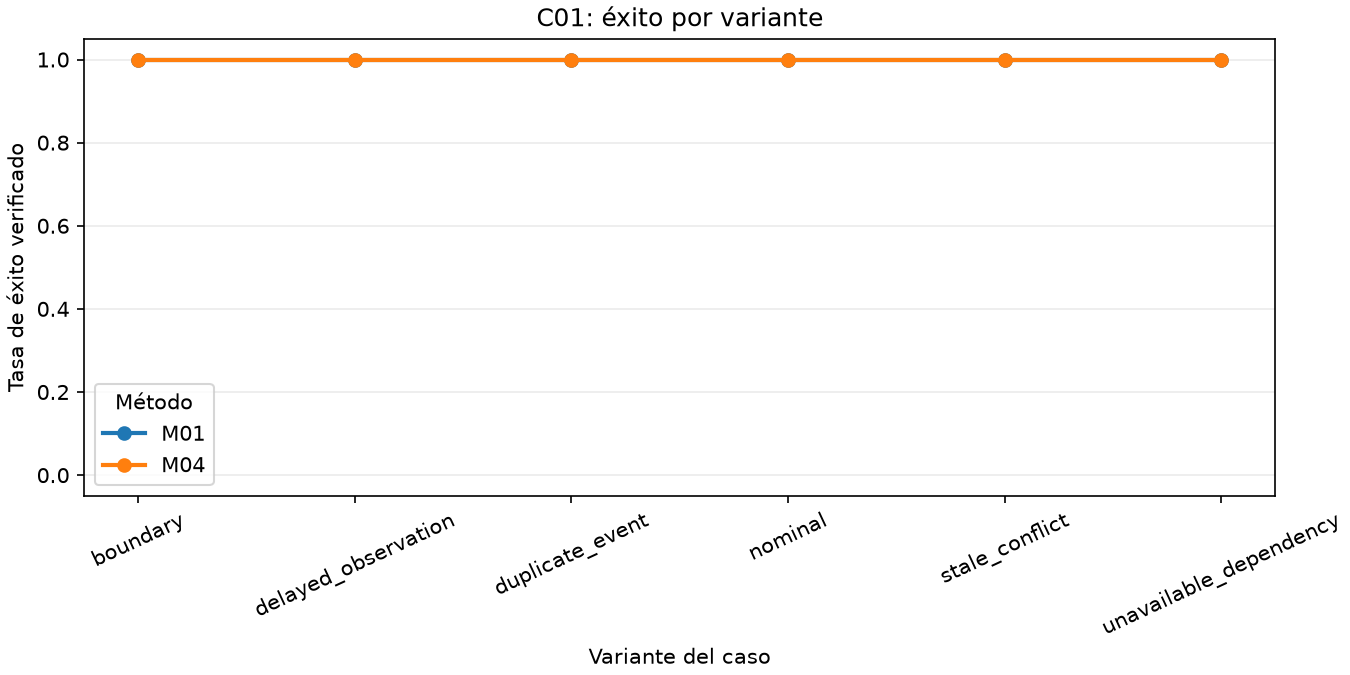

In [15]:
# Compare verified completion rates over every seed in each case variant.
methods_to_plot = selected_methods
variants = sorted({variant for _, variant in case_records})
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    rates = []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        rate = sum(bool(e['metrics']['task_success']) for e in episodes) / len(episodes) if episodes else float('nan')
        rates.append(rate)
    ax.plot(variants, rates, marker='o', linewidth=2, label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito verificado")
ax.set_xlabel("Variante del caso")
ax.set_title(sample_case + ": éxito por variante")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(title='Método' if True else 'Method')
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Para evaluación y transferencia, estas barras muestran resultados nuevos de poscondición de M01 y M04 en C01, Éxito vale 1 y falla 0. Lee el caso y la semilla antes de compararlas. En la comparación emparejada de evaluación y transferencia para C01, este episodio controlado ilustra el comportamiento, pero no es un intervalo de confianza ni establece generalización a otras tareas de software;

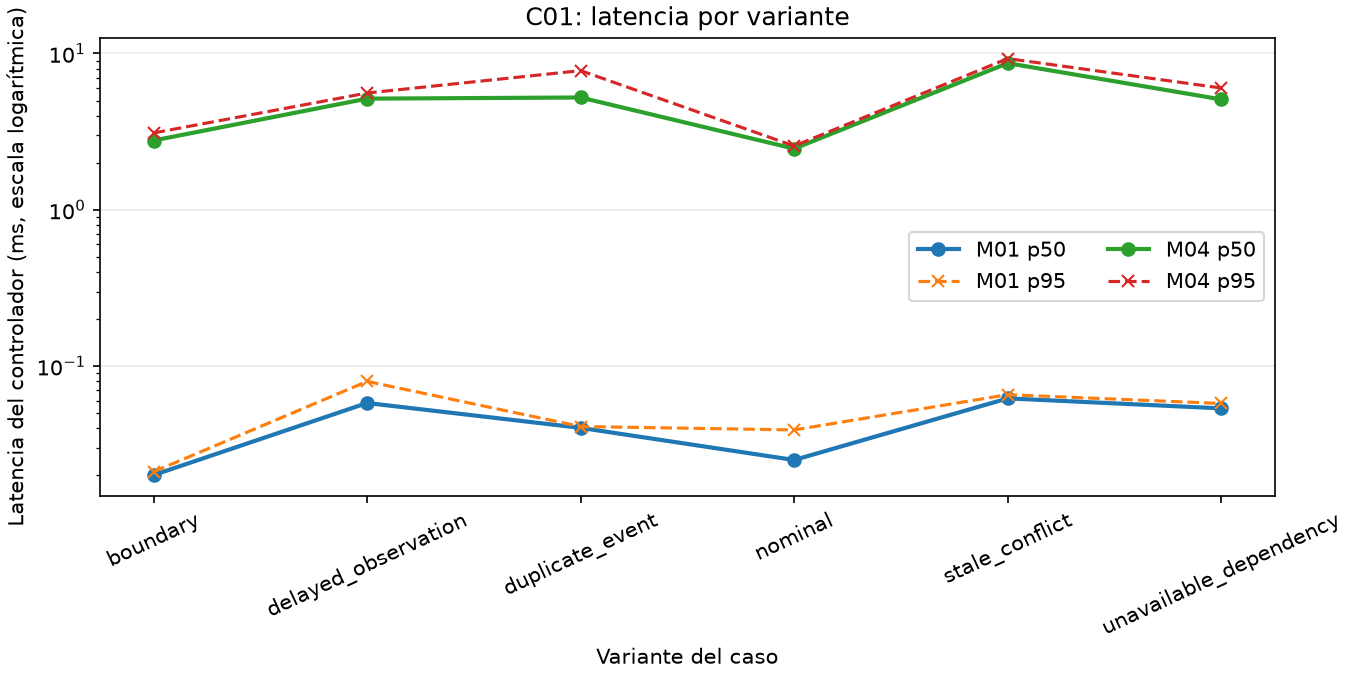

In [16]:
# Compare median and upper-tail controller time across the same case variants.
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
variants = sorted({variant for _, variant in case_records})
methods_to_plot = list(dict.fromkeys(selected_methods + ['M04']))
for method_id in methods_to_plot:
    p50, p95 = [], []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        values = sorted(e['metrics']['controller_ms'] for e in episodes)
        p50.append(values[(len(values) - 1) // 2] if values else float('nan'))
        p95.append(values[min(len(values) - 1, int(.95 * (len(values) - 1)))] if values else float('nan'))
    ax.plot(variants, p50, marker='o', linewidth=2, label=f'{method_id} p50')
    ax.plot(variants, p95, marker='x', linestyle='--', label=f'{method_id} p95')
ax.set_yscale('log')
ax.set_ylabel("Latencia del controlador (ms, escala logarítmica)")
ax.set_xlabel("Variante del caso")
ax.set_title(sample_case + ": latencia por variante")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(ncol=2)
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


La figura de nivel 3 para evaluación y transferencia lee registros canónicos de M01/M04 en C01, variante nominal y semilla 40000, luego de verificar sus hashes en la frontera de datos.

C01 es un ejemplo central;

El gráfico 3, nivel 3, resume latencia central con transferencia retenida en otro denominador para C01.

## Resultados

**Respuesta:** La comparación de nivel 3 para evaluación y transferencia contiene 2 episodios nuevos y 1 referencia XGBoost M04 en C01; esas 3 corridas emparejadas no establecen superioridad poblacional para evaluación y transferencia.

La matriz central está saturada: Siete métodos resuelven los 1; Dentro de esta comparación de evaluación y transferencia (C01), 200 episodios y solo 71/1.440 celdas método/caso/variante cambian por semilla; En la comparación emparejada de evaluación y transferencia para C01, en transferencia estructural, M04 resuelve 24/24 casos y M12 21/24; Dentro de esta comparación de evaluación y transferencia (C01), el carril semántico opaco mayor también favorece M09 frente a M12; En la comparación emparejada de evaluación y transferencia para C01, no hay respaldo para afirmar superioridad aprendida;

En la comparación emparejada de evaluación y transferencia para C01, este paso de autoría no compromete salidas generadas;

## Resumen

Un resultado central y uno de transferencia responden preguntas distintas.




## Referencias
- [TOOLSANDBOX](https://arxiv.org/abs/2408.04682) - [SWE](https://arxiv.org/abs/2310.06770) - [TAU2](https://arxiv.org/abs/2506.07982)